# Chapitre 7 - Exercices 7.1 à 7.6

Ces exercices portent sur la première moitié du chapitre : quand finetuner, goulots
mémoire, représentations numériques et quantification.

- **7.1** : dimensionner le matériel (mémoire d'inférence et de finetuning de Llama 2-13B
  et 70B, nombre de GPU) ;
- **7.2** : prompt, RAG ou finetuning ? (diagnostic de scénarios et calcul de point mort
  avec cache de prompt) ;
- **7.3** : mesurer la mémoire d'un pas d'entraînement selon l'optimiseur et le format
  (mini-lab GPU sur GPT-2) ;
- **7.4** : les pièges du FP16 : débordement, sous-dépassement des gradients et
  *loss scaling* ;
- **7.5** : quantifier à la main (absmax et zéro-point sur un petit vecteur, puis sur des
  activations positives) ;
- **7.6** : choisir une quantification sous un budget de bits (taille de groupe, schéma,
  mesures sur de vrais poids).

In [1]:
import gc
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie.plotting import INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT, annotate_bars
from aie.diagrams import Diagram
from aie import llm
from aie import ch07_finetuning as c7

warnings.filterwarnings("ignore")
c7.setup_style()
llm.seed_everything(0)
GB = 1e9

## Exercice 7.1 : Dimensionner le matériel

**Énoncé.** Une équipe hésite entre Llama 2-13B et Llama 2-70B pour un assistant
interne. Elle dispose de GPU de 24 Go, 48 Go ou 80 Go.

1. Calculer la mémoire d'inférence de chaque modèle en 16 bits avec la règle du livre
   ($N \times M \times 1{,}2$), puis en INT4 (poids seuls à 0,5 octet, même surcoût de 20 %).
2. Calculer la mémoire d'un finetuning complet avec Adam selon la convention du livre
   (tout en 16 bits) et selon la recette de précision mixte (16 octets par paramètre),
   activations non comprises.
3. Même question pour un finetuning LoRA (1 % de paramètres entraînables, recette mixte
   sur la partie entraînable, base en 16 bits) et pour QLoRA (base en 4 bits).
4. Pour chaque cas, combien de GPU de chaque taille faut-il au minimum (en supposant la
   mémoire parfaitement répartie) ?

**Rappels.** Section *Memory Math* : inférence $\approx N M \times 1{,}2$ ; entraînement =
poids + activations + gradients + états de l'optimiseur, ces deux derniers
proportionnels au nombre de paramètres **entraînables** (Adam : 2 états). Section
*Quantized LoRA* : QLoRA stocke la base en NF4 (4 bits).

**Solution.**

*1. Inférence.* 13B : $13 \times 2 \times 1{,}2 = 31{,}2$ Go ; 70B : $70 \times 2 \times 1{,}2 = 168$ Go
(en prenant les tailles nominales). En INT4 : $13 \times 0{,}5 \times 1{,}2 = 7{,}8$ Go et
$70 \times 0{,}5 \times 1{,}2 = 42$ Go.

*2. Finetuning complet.* Livre : $N \times (2 + 3 \times 2) = 8N$ octets, soit 104 Go et
560 Go. Précision mixte : $16N$, soit 208 Go et 1 120 Go.

*3. LoRA (1 %).* Base 16 bits $2N$ + $16 \times 0{,}01 N$ : $2{,}16 N$, soit 28,1 Go et 151 Go.
QLoRA : $0{,}5 N + 0{,}16 N = 0{,}66 N$, soit 8,6 Go et 46 Go.

*4.* On divise par la capacité et on arrondit au supérieur ; le code fait le tableau.

In [2]:
cases = {}
for name, N in [("Llama 2-13B", 13e9), ("Llama 2-70B", 70e9)]:
    cases[(name, "inférence 16 bits")] = c7.inference_memory(N, 2)
    cases[(name, "inférence INT4")] = c7.inference_memory(N, 0.5)
    cases[(name, "complet (livre)")] = c7.training_memory(N, recipe="livre")["total"]
    cases[(name, "complet (mixte)")] = c7.training_memory(N, recipe="mixte")["total"]
    cases[(name, "LoRA 1 %")] = 2 * N + 16 * 0.01 * N
    cases[(name, "QLoRA 1 %")] = 0.5 * N + 16 * 0.01 * N
tab = pd.DataFrame({"mémoire (Go)": {k: v / GB for k, v in cases.items()}})
for cap in [24, 48, 80]:
    tab[f"GPU {cap} Go"] = np.ceil(tab["mémoire (Go)"] / cap).astype(int)
tab.round(1)

mémoire (Go)  GPU 24 Go  GPU 48 Go  GPU 80 Go
Llama 2-13B inférence 16 bits          31.2          2          1          1
            inférence INT4              7.8          1          1          1
            complet (livre)           104.0          5          3          2
            complet (mixte)           208.0          9          5          3
            LoRA 1 %                   28.1          2          1          1
            QLoRA 1 %                   8.6          1          1          1
Llama 2-70B inférence 16 bits         168.0          7          4          3
            inférence INT4             42.0          2          1          1
            complet (livre)           560.0         24         12          7
            complet (mixte)          1120.0         47         24         14
            LoRA 1 %                  151.2          7          4          2
            QLoRA 1 %                  46.2          2          1          1

**Vérification graphique.**

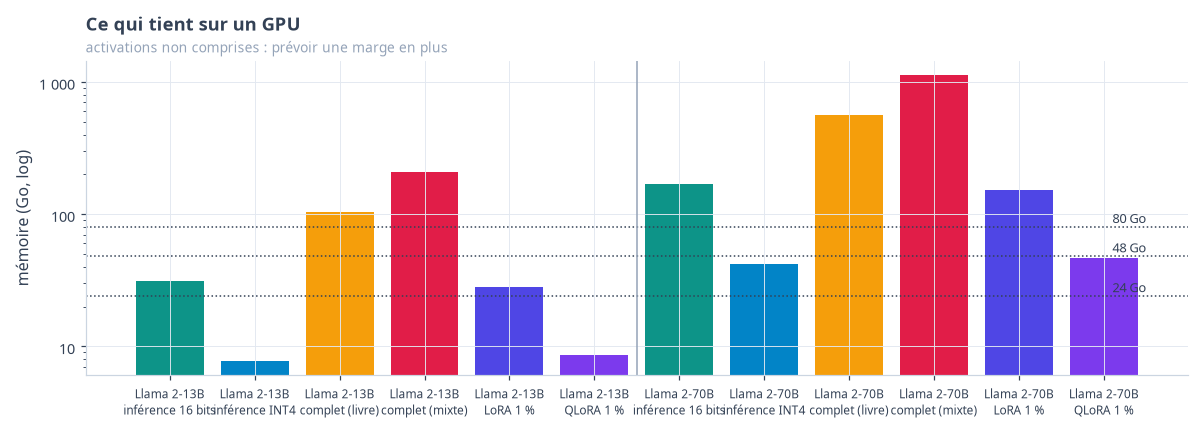

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
labels = [f"{a}\n{b}" for a, b in tab.index]
cols = [TEAL, SKY, AMBER, ROSE, INDIGO, VIOLET] * 2
ax.bar(range(len(tab)), tab["mémoire (Go)"], color=cols)
ax.set_yscale("log"); c7.sci_log(ax, "y"); c7.plain_log(ax, "y")
for cap in [24, 48, 80]:
    ax.axhline(cap, color=SLATE, ls=":", lw=1); ax.text(len(tab) - 0.5, cap * 1.07, f"{cap} Go", fontsize=8.5, ha="right")
ax.set_xticks(range(len(tab)), labels, fontsize=7.8); ax.set_ylabel("mémoire (Go, log)")
ax.axvline(5.5, color=GRAY, lw=1)
c7.title_sub(ax, "Ce qui tient sur un GPU", "activations non comprises : prévoir une marge en plus")
plt.tight_layout(); plt.show()

Conclusions : le 13B s'utilise sur un GPU de 48 Go en 16 bits (ou 24 Go en INT4) et se
finetune en QLoRA sur un GPU de 24 Go ; le 70B demande plusieurs GPU de 80 Go pour
l'inférence 16 bits, mais tient sur **un** GPU de 48 Go en QLoRA, avec très peu de marge
pour les activations. Le finetuning complet du 70B réclame une grappe de 7 à 14 GPU de
80 Go selon la recette, d'où le recours au parallélisme et au déchargement (DeepSpeed).

> **À retenir.** Les ordres de grandeur se calculent en octets par paramètre : 2,4
> (inférence 16 bits), 8 à 16 (finetuning complet), environ 2,2 (LoRA), environ 0,7 (QLoRA),
> plus les activations.

## Exercice 7.2 : Prompt, RAG ou finetuning ?

**Énoncé.**

1. Pour chacun des cas suivants, identifier le type d'échec (information ou comportement)
   et proposer la prochaine étape, en justifiant :
   a. un assistant juridique cite des articles de loi abrogés l'an dernier ;
   b. un générateur de requêtes doit écrire dans un DSL interne de 40 mots-clés, que le
      modèle invente ou mélange avec du SQL malgré 10 exemples dans le prompt ;
   c. un chatbot de support répond juste mais sur un ton trop familier, et le prompt actuel
      tient en une ligne ;
   d. un assistant médical doit résumer des comptes rendus avec un plan imposé en 6
      rubriques et ignorer les protocoles internes de l'hôpital.
2. Une application envoie 3 000 tokens d'exemples à chaque requête (plus 500 tokens
   propres à la requête, 200 tokens de sortie), avec un modèle à 1 \$ / 3 \$ par million de
   tokens (entrée / sortie). Un modèle finetuné, sans les exemples, coûte deux fois plus
   cher par token et 5 000 \$ de coût fixe. Calculer le point mort sans cache, puis avec un
   cache de prompt qui facture les tokens en cache à 10 % du prix.

**Rappels.** Section *Finetuning and RAG* : les échecs d'**information** (faits absents ou
périmés) relèvent du RAG, les échecs de **comportement** (format, style, syntaxe peu
courante) du finetuning ; on commence par un prompt systématique ; si les deux types
d'échecs coexistent, RAG d'abord. Cours 1, section 4 : calcul du point mort.

**Solution.**

*1.* a. **Information** (connaissance périmée) : RAG sur la base légale à jour ; un
finetuning ne garantirait pas l'oubli des anciennes versions et serait à refaire à chaque
réforme. b. **Comportement** (syntaxe rare, déjà testée avec des exemples) : candidat
naturel au finetuning, éventuellement complété par du décodage contraint (chapitre 2).
c. **Comportement**, mais le prompt n'a pas été travaillé : prompt systématique d'abord
(consignes de ton, exemples). d. **Les deux** : plan imposé (forme) et protocoles internes
(faits) : RAG sur les protocoles, puis finetuning si le plan n'est pas respecté.

*2.* Sans cache, coût par requête few-shot : $(3500 \times 1 + 200 \times 3)/10^6 = 0{,}0041$ \$ ;
finetuné : $(500 \times 2 + 200 \times 6)/10^6 = 0{,}0022$ \$. Économie : 0,0019 \$ par requête,
point mort $5000 / 0{,}0019 \approx 2{,}6$ millions de requêtes. Avec cache :
$(500 + 0{,}1 \times 3000) \times 1 + 200 \times 3 = 1400$, soit 0,0014 \$ < 0,0022 \$ : le modèle finetuné
n'est **jamais** rentable sur le seul critère du coût.

In [4]:
scen = [("a. lois abrogées citées", True, "information", True, False),
        ("b. DSL interne mal écrit", True, "comportement", True, False),
        ("c. ton trop familier, prompt d'une ligne", False, "comportement", True, False),
        ("d. plan imposé + protocoles internes", True, "les deux", True, False)]
display(pd.DataFrame([(s, f, c7.recommend_adaptation(p, f, h, r)) for s, p, f, h, r in scen],
                     columns=["cas", "type d'échec", "étape suivante (c7.recommend_adaptation)"]))
hyp = dict(shot_tokens=3000, base_tokens=500, out_tokens=200, price_in=1.0, price_out=3.0)
per_few = c7.fewshot_vs_finetune_cost(1, **hyp)["few-shot"]
per_ft = c7.fewshot_vs_finetune_cost(1, **hyp, ft_price_in=2.0, ft_price_out=6.0)["finetuné"]
per_cache = (500 + 0.1 * 3000) * 1.0 / 1e6 + 200 * 3.0 / 1e6
n_star = 5000 / (per_few - per_ft)
pd.DataFrame({"coût par requête (dollars)": [per_few, per_cache, per_ft],
              "point mort contre le finetuné": [f"{n_star / 1e6:.2f} M requêtes", "jamais (moins cher)", "-"]},
             index=["few-shot sans cache", "few-shot avec cache", "finetuné"])

,cas,type d'échec,étape suivante (c7.recommend_adaptation)
0,a. lois abrogées citées,information,RAG simple (BM25)
1,b. DSL interne mal écrit,comportement,finetuning (PEFT / LoRA)
2,"c. ton trop familier, prompt d'une ligne",comportement,prompt engineering systématique (avec exemples)
3,d. plan imposé + protocoles internes,les deux,RAG simple (BM25)


,coût par requête (dollars),point mort contre le finetuné
few-shot sans cache,0.0041,2.63 M requêtes
few-shot avec cache,0.0014,jamais (moins cher)
finetuné,0.0022,-


**Vérification graphique.**

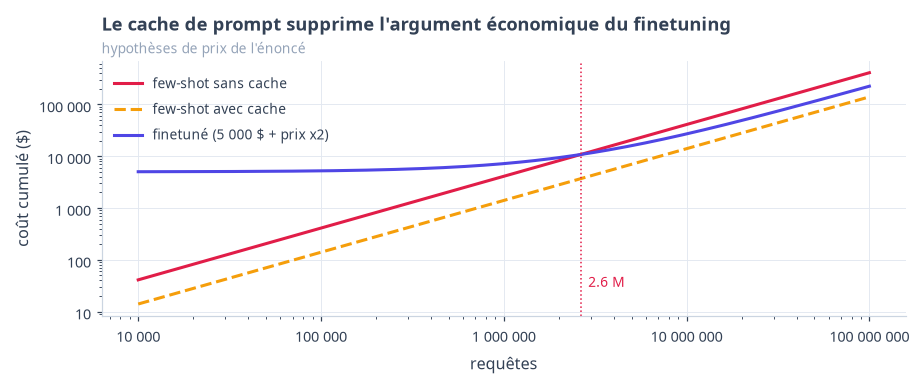

In [5]:
n = np.logspace(4, 8, 200)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.loglog(n, n * per_few, color=ROSE, label="few-shot sans cache")
ax.loglog(n, n * per_cache, color=AMBER, ls="--", label="few-shot avec cache")
ax.loglog(n, 5000 + n * per_ft, color=INDIGO, label="finetuné (5 000 \\$ + prix x2)")
ax.axvline(n_star, color=ROSE, ls=":", lw=1); ax.text(n_star * 1.1, 30, f"{n_star / 1e6:.1f} M", color=ROSE, fontsize=9)
c7.plain_log(ax, "x"); c7.plain_log(ax, "y"); ax.set_xlabel("requêtes"); ax.set_ylabel("coût cumulé (\\$)"); ax.legend(fontsize=9)
c7.title_sub(ax, "Le cache de prompt supprime l'argument économique du finetuning", "hypothèses de prix de l'énoncé")
plt.tight_layout(); plt.show()

> **À retenir.** On diagnostique le **type** d'échec avant de choisir l'outil, et l'on
> n'oublie pas l'étape « prompt systématique ». L'argument du coût en tokens ne tient plus
> guère avec le cache de prompt ; les vraies raisons de finetuner sont la qualité et la forme.

## Exercice 7.3 : Mesurer la mémoire d'un pas d'entraînement

**Énoncé.** Pour GPT-2 (124,4 M paramètres), prévoir puis mesurer la mémoire des poids,
des gradients et des états de l'optimiseur pour quatre configurations : (a) FP32 + SGD
avec momentum, (b) FP32 + Adam, (c) BF16 + Adam (tout en BF16), (d) BF16 + Adam en ne
rendant entraînables que les couches de normalisation et les biais (à la BitFit élargi).
Commenter les écarts.

**Rappels.** Cours 2, sections 1 à 3 : par paramètre entraînable, un gradient et $k$
états ($k = 1$ pour le momentum, 2 pour Adam), dans le format des poids (PyTorch crée
gradients et états dans le dtype du paramètre) ; un paramètre gelé ne coûte que son poids.
`c7.measure_train_step` isole ces postes.

**Solution.** Prévisions, avec $N = 124{,}4$ M : (a) poids $4N$ = 0,50 Go, gradients 0,50,
états 0,50 ; (b) états 1,00 Go ; (c) tout est divisé par deux : 0,25 / 0,25 / 0,50 ;
(d) poids 0,25 Go, et gradients et états ne portent que sur les biais et les
normalisations (environ 0,1 M paramètres) : quasi nuls.

In [6]:
from transformers import AutoModelForCausalLM, AutoTokenizer

tok_g = AutoTokenizer.from_pretrained("gpt2")
ids = tok_g(" ".join(c7.TEXTES_EVAL) * 4, return_tensors="pt")["input_ids"][:, :128].repeat(2, 1)


def measure(cfg):
    dtype = torch.float32 if "FP32" in cfg else torch.bfloat16
    model = AutoModelForCausalLM.from_pretrained("gpt2", dtype=dtype).cuda()
    if "biais" in cfg:
        for n_, p in model.named_parameters():
            p.requires_grad_(n_.endswith(".bias") or ".ln_" in n_)
    opt = (lambda ps: torch.optim.SGD(ps, lr=1e-4, momentum=0.9)) if "SGD" in cfg else (lambda ps: torch.optim.Adam(ps, lr=1e-5))
    batch = {"input_ids": ids.cuda(), "labels": ids.cuda()}
    r = c7.measure_train_step(model, batch, opt)
    r["entraînables"] = sum(p.numel() for p in model.parameters() if p.requires_grad)
    del model; gc.collect(); torch.cuda.empty_cache()
    return r


llm.free_gpu()
cfgs = {"(a) FP32 + SGD momentum": (4, 1), "(b) FP32 + Adam": (4, 2), "(c) BF16 + Adam": (2, 2),
        "(d) BF16 + Adam, biais et normes": (2, 2)}
rows = []
N = 124_439_808
for cfg, (b_, k) in cfgs.items():
    r = c7.gpu_retry(measure, cfg)
    nt = r["entraînables"]
    rows.append({"configuration": cfg, "entraînables": f"{nt / 1e6:.2f} M",
                 "poids prévu / mesuré (Go)": f"{b_ * N / GB:.3f} / {r['poids'] / GB:.3f}",
                 "gradients prévu / mesuré": f"{b_ * nt / GB:.3f} / {r['gradients'] / GB:.3f}",
                 "états prévu / mesuré": f"{k * b_ * nt / GB:.3f} / {r[chr(233) + 'tats de l' + chr(39) + 'optimiseur'] / GB:.3f}"})
pd.DataFrame(rows).set_index("configuration")

,entraînables,poids prévu / mesuré (Go),gradients prévu / mesuré,états prévu / mesuré
configuration,,,,
(a) FP32 + SGD momentum,124.44 M,0.498 / 0.499,0.498 / 0.504,0.498 / 0.517
(b) FP32 + Adam,124.44 M,0.498 / 0.518,0.498 / 0.503,0.996 / 0.998
(c) BF16 + Adam,124.44 M,0.249 / 0.274,0.249 / 0.261,0.498 / 0.510
"(d) BF16 + Adam, biais et normes",0.12 M,0.249 / 0.274,0.000 / 0.000,0.000 / 0.000


**Vérification.** Les mesures coïncident avec les prévisions à quelques mégaoctets près
(arrondis de l'allocateur de PyTorch, qui réserve par blocs). Deux remarques :

- (c) est la recette « tout en 16 bits » du livre ; elle est risquée pour l'entraînement,
  car les petites mises à jour se perdent en BF16 (cours 2, section 4) : la recette mixte
  ajoute une copie FP32, d'où 16 octets par paramètre ;
- (d) montre que le coût d'un paramètre gelé se limite à son poids : la mémoire de
  l'optimiseur devient négligeable, ce qui est tout l'intérêt de PEFT.

> **À retenir.** Mémoire des gradients et des états = (nombre de paramètres entraînables)
> $\times$ (octets par valeur) $\times$ (1 + nombre d'états). Elle se prévoit exactement.